In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [4]:
train_loaded = pd.read_csv(r"train.csv")
test_loaded  = pd.read_csv(r"test.csv")

X_train_loaded = train_loaded.drop('Potability', axis=1)
y_train_loaded = train_loaded['Potability']

X_test_loaded = test_loaded.drop('Potability', axis=1)
y_test_loaded = test_loaded['Potability']

# Train Random Forest Model
model = RandomForestClassifier(n_estimators=200, random_state=42)
model.fit(X_train_loaded, y_train_loaded)

# Predict Test Set for Model Validation
y_pred = model.predict(X_test_loaded)
accuracy = accuracy_score(y_test_loaded, y_pred)

print("Accuracy:", accuracy)


Accuracy: 0.8388791593695272


In [5]:
test_loaded['Potability_Pred'] = y_pred

test_loaded.to_csv(r"test_pred.csv", index=False)

print("Saved predictions to test_pred.csv")

Saved predictions to test_pred.csv


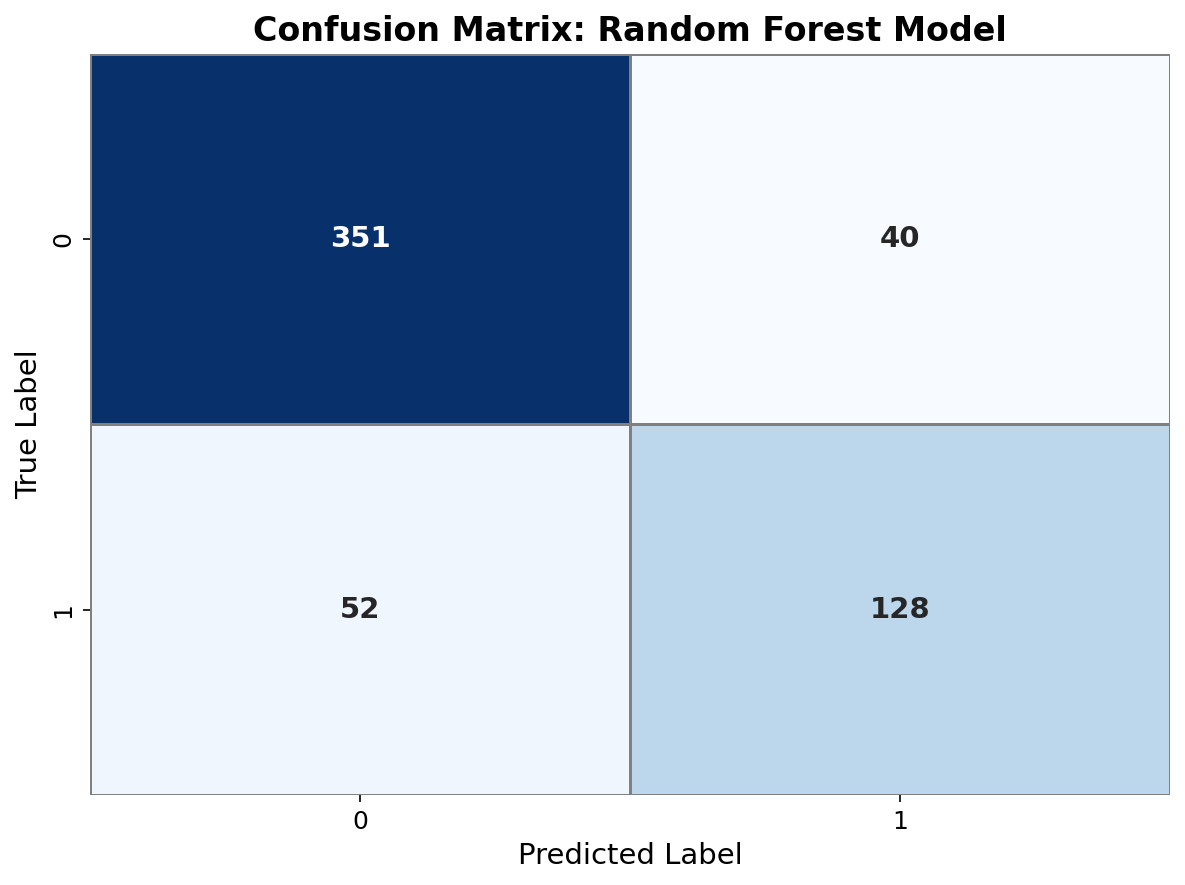

Saved predictions to test_pred.csv and confusion_matrix.png


In [6]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generate Confusion Matrix

cm = confusion_matrix(y_test_loaded, y_pred)

plt.figure(figsize=(8,6), dpi=150)  # high-quality output
sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            linewidths=0.5,
            linecolor='gray',
            cbar=False,
            annot_kws={"size": 14, "weight": "bold"})

plt.title("Confusion Matrix: Random Forest Model", fontsize=16, weight="bold")
plt.ylabel("True Label", fontsize=14)
plt.xlabel("Predicted Label", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()

plt.savefig(r"confusion_matrix.png",
            dpi=300, bbox_inches='tight')

plt.show()

test_loaded['Potability_Pred'] = y_pred
test_loaded.to_csv(r"test_pred.csv", index=False)

print("Saved predictions to test_pred.csv and confusion_matrix.png")

ROC-AUC: 0.8915814151747655


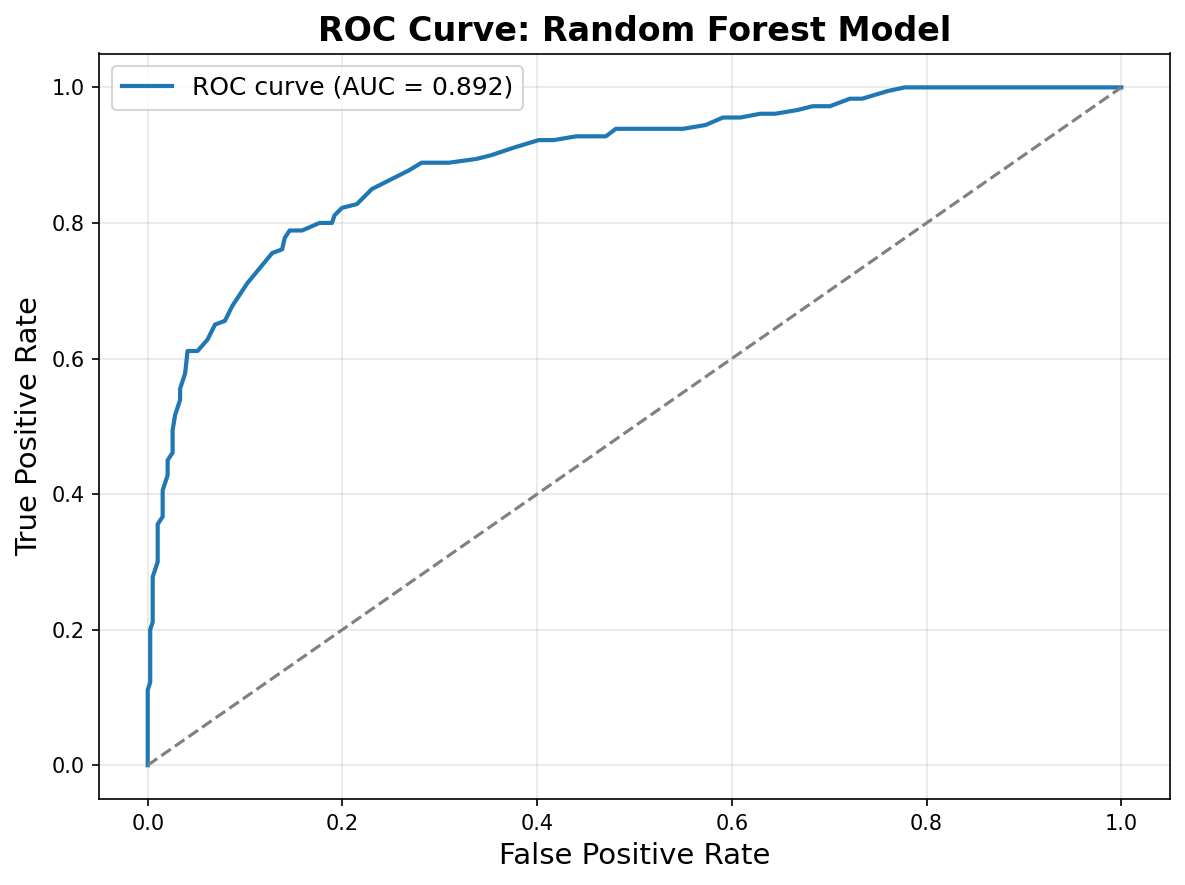

In [7]:
from sklearn.metrics import roc_auc_score, roc_curve

# Generate ROC Curve

y_prob = model.predict_proba(X_test_loaded)[:, 1]
roc_auc = roc_auc_score(y_test_loaded, y_prob)
print("ROC-AUC:", roc_auc)

fpr, tpr, _ = roc_curve(y_test_loaded, y_prob)

plt.figure(figsize=(8,6), dpi=150)
plt.plot(fpr, tpr, linewidth=2, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate", fontsize=14)
plt.ylabel("True Positive Rate", fontsize=14)
plt.title("ROC Curve: Random Forest Model", fontsize=16, weight="bold")
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(r"C:\Users\debna\Drinking_water\roc_curve.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [8]:
import joblib

# Save trained model as a PKL file
model_path = r"RandomForest_Potability.pkl"

joblib.dump(model, model_path)

print(f"Model saved successfully: {model_path}")

Model saved successfully: RandomForest_Potability.pkl
